# Synthetic clinical dataset

This repository uses one canonical synthetic data contract throughout. The full dataset in `data/synthetic/` is exactly the supplied generator output; `data/toy/` is a deterministic small subset with the same schema for fast model tutorials.

The simulator is deliberately richer than a regular time-series table: cohort entry can occur late in life, event times and measurement times are irregular, covariates can update asynchronously, and hidden pre-study events exist only as oracle truth.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
from lifetime_clinical.data import load_dataset, load_splits
from lifetime_clinical.data.synthetic import SyntheticConfig, generate_dataset
from lifetime_clinical.visualization import plot_patient_timeline

In [2]:
DATA=ROOT/"data"/"synthetic"
dataset=load_dataset(DATA); splits=load_splits(DATA)
summary=pd.DataFrame({
    "table":["patients","events","measurements","dynamic_covariates","pre_study_events"],
    "rows":[len(dataset.patients),len(dataset.events),len(dataset.measurements),len(dataset.dynamic_covariates),len(dataset.pre_study_events)]
})
summary

,table,rows
0,patients,1300
1,events,15891
2,measurements,38529
3,dynamic_covariates,19803
4,pre_study_events,19707


## Tables

- `patients.csv`: one row per patient, including cohort-entry age and observation-window end.
- `events.csv`: observed recurrent clinical events inside the study window.
- `measurements.csv`: irregular BP, glucose and creatinine measurements; panels can be linked to events or occur independently.
- `dynamic_covariates.csv`: asynchronous updates such as employment, marital status and EHR-history text.
- `pre_study_events.csv`: **oracle-only** simulated history before entry. It is useful to demonstrate the missing-prehistory problem but must never be used as observed training history.
- `splits.json`: patient-level train/validation/test split.

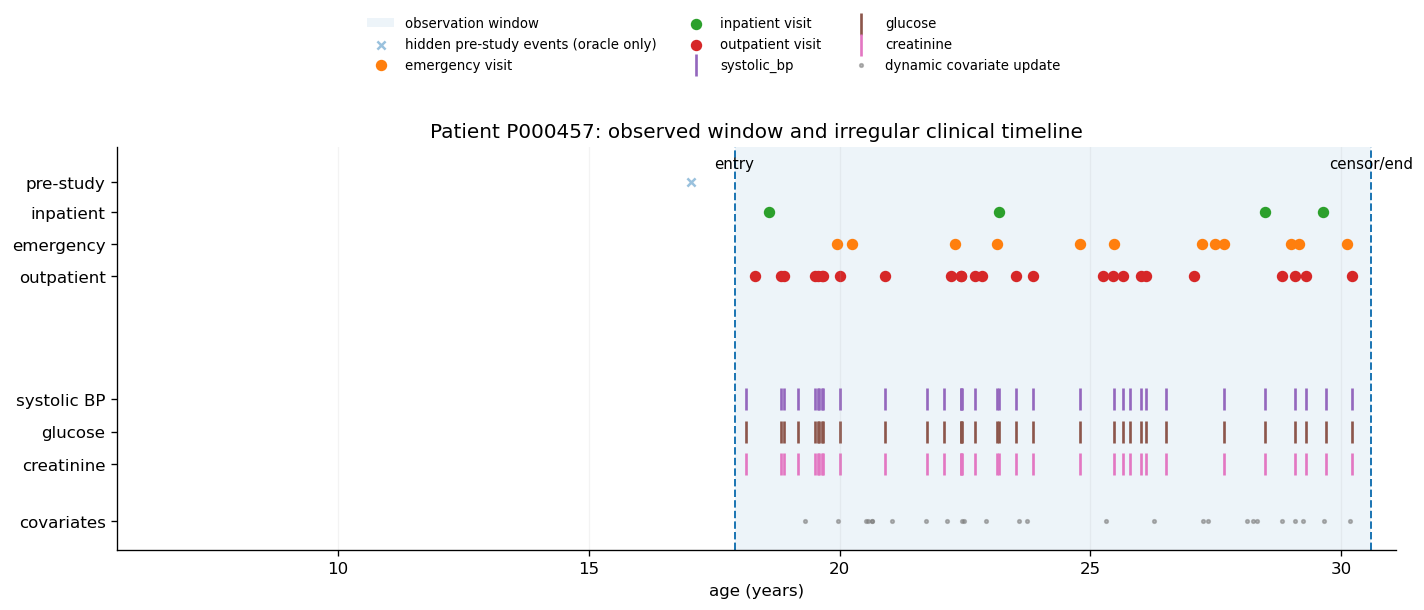

In [3]:
pid = dataset.patients.sort_values("n_observed_events", ascending=False).iloc[25].patient_id
fig, ax = plt.subplots(figsize=(12, 5.2))
plot_patient_timeline(dataset, pid, ax=ax, show_hidden=True)
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5, .98),
           ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0, 1, .82))
plt.show()


The shaded interval is the **observation window**. Crosses before entry are hidden simulator truth. The model only knows that the patient enters at a given age; it does not know the events that occurred beforehand.

This distinction matters:

\[
\text{unobserved before entry}\neq\text{no events before entry}.
\]

The end of follow-up is similarly not an event unless death is explicitly observed. For event-time models it produces a right-censoring survival term.

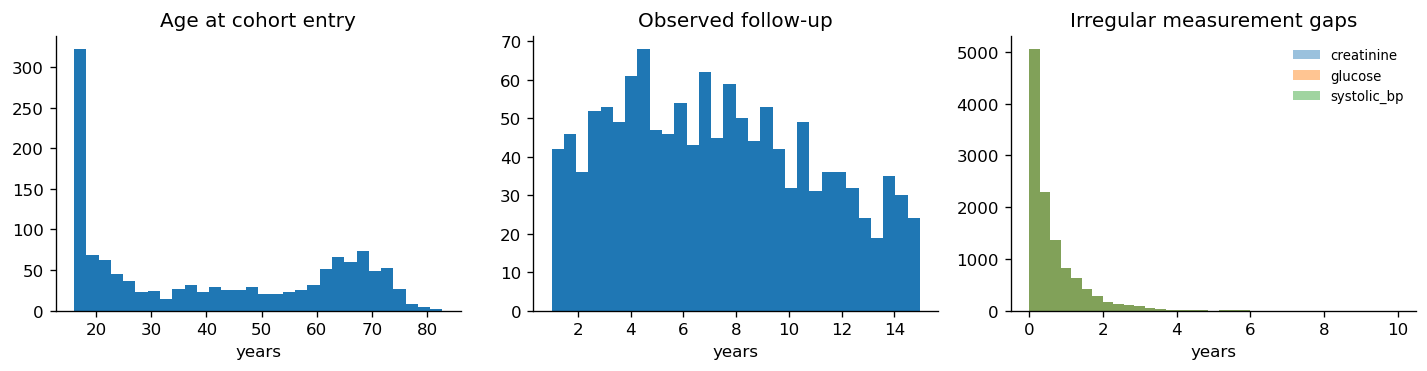

In [4]:
p=dataset.patients
fig,axes=plt.subplots(1,3,figsize=(12,3.2))
axes[0].hist(p.start_study_age,bins=30); axes[0].set(title="Age at cohort entry",xlabel="years")
axes[1].hist(p.followup_years,bins=30); axes[1].set(title="Observed follow-up",xlabel="years")
for variable,grp in dataset.measurements.sort_values("measurement_date").groupby("variable"):
    gaps=grp.groupby("patient_id").measurement_age.diff().dropna(); axes[2].hist(gaps,bins=35,alpha=.45,label=variable)
axes[2].set(title="Irregular measurement gaps",xlabel="years"); axes[2].legend(frameon=False,fontsize=8)
plt.tight_layout(); plt.show()

## Missingness is structural, not just `NaN`

The dataset contains several different notions that should not be collapsed:

1. a variable was never measured at a particular age;
2. a dynamic covariate was recorded later and therefore was unknown earlier;
3. EHR text may explicitly be missing;
4. the whole pre-entry history is unobserved;
5. the final event time is censored by end of follow-up.

The GP branch treats an unmeasured physiological time as simply **unobserved**; it does not fill a dense matrix. TPP-B/C use the latest known physiological state plus masks/staleness as context, and their continuous feature-flow tutorial begins only once all three continuous variables have been observed.

In [5]:
config=pd.Series(dataset.config.__dict__).to_frame("value")
config.loc[["n_samples","seed","followup_years","mean_events","count_distribution","measurement_schedule","measurement_probability","independent_measurement_rate","pre_study_event_rate"]]

,value
n_samples,1300
seed,42
followup_years,"[1.0, 15.0]"
mean_events,12.0
count_distribution,negative_binomial
measurement_schedule,mixed
measurement_probability,0.5
independent_measurement_rate,0.5
pre_study_event_rate,0.6


## Controlling generation

The simulator lives in `lifetime_clinical.data.synthetic.SyntheticConfig`; `configs/synthetic_data.json` exposes the same settings. The main controls are:

- cohort size and seed;
- age distribution and follow-up duration;
- event-count distribution and event-type weights;
- hidden pre-study event rate;
- event-linked vs independent measurement schedules;
- probability/rate of measurement panels;
- dynamic-covariate update rates.

Generate a separate dataset from the repository root:

```bash
python scripts/generate_synthetic_data.py --config configs/synthetic_data.json --output data/generated_synthetic
```

The CLI writes CSV tables and metadata; it does not create patient splits or the toy subset.

To use the generator directly in Python:

```python
from lifetime_clinical.data.synthetic import SyntheticConfig, generate_dataset

generated = generate_dataset(SyntheticConfig(n_samples=100, seed=42))
```


In [6]:
toy=load_dataset(ROOT/"data"/"toy"); toy_splits=load_splits(ROOT/"data"/"toy")
print("toy patients:",len(toy.patients), {k:len(v) for k,v in toy_splits.items()})
print("Same measurement variables:", sorted(toy.measurements.variable.unique()))

toy patients: 130 {'train': 100, 'validation': 20, 'test': 10}
Same measurement variables: ['creatinine', 'glucose', 'systolic_bp']


The remaining notebooks use `data/toy/` only for speed. No schema or modelling assumption changes between the toy and full synthetic cohort.